In [1]:
# 파이썬 환경에 seaborn(데이터 시각화 라이브러리) 설치  !pip install seaborn
# 파이썬 환경에 scipy(수치 계산/과학 계산 라이브러리) 설치 !pip install scipy
# 아래 설치할때는 주석코드가 없어야 함
# ! → Colab/주피터에서 셸 명령 실행

In [2]:
!pip install seaborn # # seaborn 설치
!pip install scipy # scipy 설치
!{sys.executable} -m pip install --upgrade scipy # 현재 사용 중인 파이썬 환경 기준으로 scipy 업그레이드 설치


/bin/bash: line 1: {sys.executable}: command not found


| 코드                     | 의미                   |
| ---------------------- | -------------------- |
| `!pip install seaborn` | seaborn 시각화 라이브러리 설치 |
| `!pip install scipy`   | scipy 수학/통계 라이브러리 설치 |
| `sys.executable`       | 현재 실행 중인 파이썬 경로      |
| `--upgrade scipy`      | scipy 최신 버전으로 업데이트   |


In [3]:
# # pip(파이썬 패키지 설치 프로그램)를 최신 버전으로 업그레이드
!python -m pip install --upgrade pip

In [5]:
# 구글 드라이브 연결
from google.colab import drive
drive.mount('/content/drive')

# 운영체제(OS) 관련 기능 사용
import os

# 작업 위치를 Colab Notebooks/Data_Analysis 폴더로 이동
os.chdir('/content/drive/MyDrive/Colab Notebooks/Data_Analysis/DA_01')

# 현재 작업 위치 출력
print(os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/Colab Notebooks/Data_Analysis/DA_01


In [6]:
import os
os.listdir('/content')

['.config', 'drive', 'sample_data']

In [7]:
# start.py 파일을 실행
# 데이터 분석에 필요한 공통 라이브러리(pandas, numpy 등)와 기본 설정을 한 번에 불러옴
# %run = 다른 파이썬(.py) 파일을 현재 노트북에서 실행하는 명령어
%run start.py

# start.py 안에 뭐가 들어 있는지 확인


In [8]:
# start.py 파일의 전체 내용 확인,
%cat start.py

# ============================================================
# 데이터 분석 수업 공통 라이브러리 파일
# ------------------------------------------------------------
# 이 파일은 각 Colab/Jupyter 노트북에서 `%run start.py`로 실행한다.
# 즉, 수업에서 반복해서 사용하는 라이브러리를 한 번에 준비하는 역할이다.
#
# [핵심 개념]
# pandas      : 표(DataFrame) 데이터 처리
# numpy       : 숫자/배열 계산
# seaborn     : 통계 그래프
# matplotlib  : 그래프 출력
# scipy       : 통계 계산
# sklearn     : 머신러닝 전처리/회귀/군집
# statsmodels : 회귀 결과를 통계적으로 자세히 확인
# ============================================================

# 경고 메시지 무시 (출력 화면을 깔끔하게 하기 위해)
import warnings
warnings.filterwarnings(action='ignore') 


# 데이터 분석/처리를 위한 라이브러리
import pandas as pd    # 데이터프레임(표) 처리
import numpy as np       # 수치 연산 라이브러리   
import seaborn as sns    # 통계 시각화 라이브러리
import matplotlib.pyplot as plt  # 그래프 시각화 라이브러리
import scipy as sp     # 과학/통계 계산 라이브러리

# 데이터 전처리용
from sklearn.preprocessing import StandardScaler   # 표준화(평균 0, 표준편차 1로 변환)

# 회귀 분석
from sklearn.linear_model import LinearRegression   # 선형 회귀 분석


### mpg 데이터셋 이용

##### mpg 데이터 읽어오기
```
Seaborn에서 학습용으로 제공하는 온라인 예제 데이터셋을 가져오는 것
mpg_data = sns.load_dataset("mpg")

흐름
Seaborn 예제 데이터 저장소(인터넷)
        ↓
sns.load_dataset("mpg")
        ↓
Pandas DataFrame으로 가져옴
        ↓
mpg_data에 저장
```
### Seaborn 예제 데이터 저장소
https://github.com/mwaskom/seaborn-data?utm_source=chatgpt.com

##### mpg는 자동차의 연비, 실린더 수, 배기량, 마력, 무게, 생산연도, 생산국가 등의 정보를 담은 자동차 데이터

In [9]:
# seaborn 사용 가능하게 연결 (start.py에 코드가 들어있음, 없다면 이렇게 하나씩 불러와야함)
import seaborn as sns

In [10]:
mpg_data = sns.load_dataset("mpg")  # mpg 자동차 연비
mpg_data

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino
...,...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86.0,2790,15.6,82,usa,ford mustang gl
394,44.0,4,97.0,52.0,2130,24.6,82,europe,vw pickup
395,32.0,4,135.0,84.0,2295,11.6,82,usa,dodge rampage
396,28.0,4,120.0,79.0,2625,18.6,82,usa,ford ranger


| 연비(mpg) | 실린더 수 | 배기량   | 마력    | 무게   | 가속 성능 | 모델 연도 | 제조국    | 자동차 이름                    |
| ------- | ----- | ----- | ----- | ---- | ----- | ----- | ------ | ------------------------- |
| 18.0    | 8     | 307.0 | 130.0 | 3504 | 12.0  | 70    | usa    | chevrolet chevelle malibu |
| 15.0    | 8     | 350.0 | 165.0 | 3693 | 11.5  | 70    | usa    | buick skylark 320         |
| 18.0    | 8     | 318.0 | 150.0 | 3436 | 11.0  | 70    | usa    | plymouth satellite        |
| 16.0    | 8     | 304.0 | 150.0 | 3433 | 12.0  | 70    | usa    | amc rebel sst             |
| 17.0    | 8     | 302.0 | 140.0 | 3449 | 10.5  | 70    | usa    | ford torino               |
| ...     | ...   | ...   | ...   | ...  | ...   | ...   | ...    | ...                       |
| 27.0    | 4     | 140.0 | 86.0  | 2790 | 15.6  | 82    | usa    | ford mustang gl           |
| 44.0    | 4     | 97.0  | 52.0  | 2130 | 24.6  | 82    | europe | vw pickup                 |
| 32.0    | 4     | 135.0 | 84.0  | 2295 | 11.6  | 82    | usa    | dodge rampage             |
| 28.0    | 4     | 120.0 | 79.0  | 2625 | 18.6  | 82    | usa    | ford ranger               |
| 31.0    | 4     | 119.0 | 82.0  | 2720 | 19.4  | 82    | usa    | chevy s-10                |


| 컬럼명            | 한글 의미  | 쉬운 설명                    |
| -------------- | ------ | ------------------------ |
| `mpg`          | 연비     | 자동차가 연료를 얼마나 효율적으로 사용하는가 |
| `cylinders`    | 실린더 수  | 엔진 내부 실린더 개수             |
| `displacement` | 배기량    | 엔진 크기                    |
| `horsepower`   | 마력     | 자동차 힘(출력)                |
| `weight`       | 차량 무게  | 자동차 무게                   |
| `acceleration` | 가속 성능  | 속도를 올리는 능력               |
| `model_year`   | 모델 연도  | 자동차 생산 연도                |
| `origin`       | 생산 국가  | 자동차 제작 국가                |
| `name`         | 자동차 이름 | 차량 모델명                   |


origin 값 의미
| 값        | 의미 |
| -------- | -- |
| `usa`    | 미국 |
| `europe` | 유럽 |
| `japan`  | 일본 |


데이터 전체 의미
| 내용          | 설명           |
| ----------- | ------------ |
| 행(row)      | 자동차 한 대 정보   |
| 열(column)   | 자동차 속성 정보    |
| `398 rows`  | 자동차 데이터 398개 |
| `9 columns` | 속성 9개        |


## 데이터 상태 확인
- `info()` : 열 이름, 데이터 타입, 결측치 여부 등을 확인한다.
- `describe()` : **숫자형 열 중심으로** 평균, 표준편차, 최솟값, 최댓값, 사분위수를 보여준다.
- 분석을 시작하면 모델부터 만드는 것이 아니라 **데이터 상태를 먼저 확인**하는 습관이 중요하다.


In [11]:
# info()로 열 이름, 자료형, 결측치 여부를 확인
mpg_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    object 
 8   name          398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB


| 내용         | 설명             |
| ---------- | -------------- |
| 전체 데이터 개수  | 398개           |
| 전체 컬럼 개수   | 9개             |
| float64    | 실수형 데이터        |
| int64      | 정수형 데이터        |
| object     | 문자열 데이터        |
| horsepower | 결측치(누락 데이터) 존재 |


memory usage 의미
| 항목                    | 의미                  |
| --------------------- | ------------------- |
| memory usage: 28.1 KB | 현재 데이터가 사용하는 메모리 크기 |


## 결측치(NaN)
- 결측치는 값이 비어 있는 상태이다.
- `isnull().sum()`으로 열별 결측치 개수를 확인할 수 있다.
- `dropna()`는 결측치가 있는 데이터를 제거하고,
- `fillna()`는 평균·중앙값 등 다른 값으로 채운다.
- 어떤 방법이 무조건 정답은 아니고 **데이터의 의미를 보고 결정**해야 한다.


In [12]:
# 결측치(NaN)가 어디에 얼마나 있는지 확인
mpg_data.isnull().sum()   # 결측치 갯수

,0
mpg,0
cylinders,0
displacement,0
horsepower,6
weight,0
acceleration,0
model_year,0
origin,0
name,0


| 속성명                 | 결측치 개수 |
| ------------------- | ------ |
| 연비(mpg)             | 0      |
| 실린더 수(cylinders)    | 0      |
| 배기량(displacement)   | 0      |
| 마력(horsepower)      | 6      |
| 자동차 무게(weight)      | 0      |
| 가속 성능(acceleration) | 0      |
| 모델 연도(model_year)   | 0      |
| 제조국(origin)         | 0      |
| 자동차 이름(name)        | 0      |


In [13]:
# 결측치(NaN)가 어디에 얼마나 있는지 확인
# 결측치를 다른 값으로 채우는 전처리
# 평균값을 구해서 채움
# inplace=True 있으면 원본의 값을 바꿈
mpg_data['horsepower'].fillna(mpg_data['horsepower'].mean(), inplace=True)
mpg_data.isnull().sum()

,0
mpg,0
cylinders,0
displacement,0
horsepower,0
weight,0
acceleration,0
model_year,0
origin,0
name,0


In [14]:
##### 범주형 데이터(origin)를 숫자로 변환 ('usa':0, 'europe':1, 'japan': 2)

In [15]:
# 'origin_encoded'(오리진 인코디드) 원본을 손상시키지 않고 , 덮어씌우지 않고, 머신러닝은 문자 이해 못함, 문자 → 숫자로 바꿔서 모델이 이해하게 만드는 코드
mpg_data['origin_encoded'] = mpg_data['origin'].map({'usa': 0, 'europe': 1, 'japan': 2})
mpg_data

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name,origin_encoded
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu,0
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320,0
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite,0
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst,0
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino,0
...,...,...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86.0,2790,15.6,82,usa,ford mustang gl,0
394,44.0,4,97.0,52.0,2130,24.6,82,europe,vw pickup,1
395,32.0,4,135.0,84.0,2295,11.6,82,usa,dodge rampage,0
396,28.0,4,120.0,79.0,2625,18.6,82,usa,ford ranger,0


```text
mpg_data['origin_encoded'] = mpg_data['origin'].map(
    {
        'usa': 0,
        'europe': 1,
        'japan': 2
    }
)
```
| 코드           | 의미             |
| ------------ | -------------- |
| `map()`      | 문자 데이터를 숫자로 변환 |
| `usa → 0`    | 미국 데이터를 0으로 변경 |
| `europe → 1` | 유럽 데이터를 1로 변경  |
| `japan → 2`  | 일본 데이터를 2로 변경  |


| 이유      | 설명                 |
| ------- | ------------------ |
| 머신러닝 사용 | AI는 문자보다 숫자 계산을 잘함 |
| 모델 학습   | 숫자 형태가 계산하기 쉬움     |
| 전처리 과정  | 문자열 → 숫자 변환 과정     |


| 연비   | 실린더 수 | 배기량   | 마력    | 무게   | 가속 성능 | 모델 연도 | 제조국    | 자동차 이름                    | 제조국 인코딩 |
| ---- | ----- | ----- | ----- | ---- | ----- | ----- | ------ | ------------------------- | ------- |
| 18.0 | 8     | 307.0 | 130.0 | 3504 | 12.0  | 70    | usa    | chevrolet chevelle malibu | 0       |
| 15.0 | 8     | 350.0 | 165.0 | 3693 | 11.5  | 70    | usa    | buick skylark 320         | 0       |
| 18.0 | 8     | 318.0 | 150.0 | 3436 | 11.0  | 70    | usa    | plymouth satellite        | 0       |
| 16.0 | 8     | 304.0 | 150.0 | 3433 | 12.0  | 70    | usa    | amc rebel sst             | 0       |
| 17.0 | 8     | 302.0 | 140.0 | 3449 | 10.5  | 70    | usa    | ford torino               | 0       |
| ...  | ...   | ...   | ...   | ...  | ...   | ...   | ...    | ...                       | ...     |
| 27.0 | 4     | 140.0 | 86.0  | 2790 | 15.6  | 82    | usa    | ford mustang gl           | 0       |
| 44.0 | 4     | 97.0  | 52.0  | 2130 | 24.6  | 82    | europe | vw pickup                 | 1       |
| 32.0 | 4     | 135.0 | 84.0  | 2295 | 11.6  | 82    | usa    | dodge rampage             | 0       |
| 28.0 | 4     | 120.0 | 79.0  | 2625 | 18.6  | 82    | usa    | ford ranger               | 0       |
| 31.0 | 4     | 119.0 | 82.0  | 2720 | 19.4  | 82    | usa    | chevy s-10                | 0       |


제조국 인코딩 의미
| 제조국    | 숫자 변환 값 |
| ------ | ------- |
| usa    | 0       |
| europe | 1       |
| japan  | 2       |


##### 원하는 항목만 선택

In [16]:
subset = mpg_data[['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration',
                                                                   'model_year', 'origin_encoded']]
subset

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin_encoded
0,18.0,8,307.0,130.0,3504,12.0,70,0
1,15.0,8,350.0,165.0,3693,11.5,70,0
2,18.0,8,318.0,150.0,3436,11.0,70,0
3,16.0,8,304.0,150.0,3433,12.0,70,0
4,17.0,8,302.0,140.0,3449,10.5,70,0
...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86.0,2790,15.6,82,0
394,44.0,4,97.0,52.0,2130,24.6,82,1
395,32.0,4,135.0,84.0,2295,11.6,82,0
396,28.0,4,120.0,79.0,2625,18.6,82,0


| 연비   | 실린더 수 | 배기량   | 마력    | 무게   | 가속 성능 | 모델 연도 | 제조국 인코딩 |
| ---- | ----- | ----- | ----- | ---- | ----- | ----- | ------- |
| 18.0 | 8     | 307.0 | 130.0 | 3504 | 12.0  | 70    | 0       |
| 15.0 | 8     | 350.0 | 165.0 | 3693 | 11.5  | 70    | 0       |
| 18.0 | 8     | 318.0 | 150.0 | 3436 | 11.0  | 70    | 0       |
| 16.0 | 8     | 304.0 | 150.0 | 3433 | 12.0  | 70    | 0       |
| 17.0 | 8     | 302.0 | 140.0 | 3449 | 10.5  | 70    | 0       |
| ...  | ...   | ...   | ...   | ...  | ...   | ...   | ...     |
| 27.0 | 4     | 140.0 | 86.0  | 2790 | 15.6  | 82    | 0       |
| 44.0 | 4     | 97.0  | 52.0  | 2130 | 24.6  | 82    | 1       |
| 32.0 | 4     | 135.0 | 84.0  | 2295 | 11.6  | 82    | 0       |
| 28.0 | 4     | 120.0 | 79.0  | 2625 | 18.6  | 82    | 0       |
| 31.0 | 4     | 119.0 | 82.0  | 2720 | 19.4  | 82    | 0       |


## 표준화(StandardScaler)
- 키(cm), 몸무게(kg), 이용기간(일)처럼 단위와 숫자 크기가 다르면 큰 숫자가 분석에 더 큰 영향을 줄 수 있다.
- `StandardScaler`는 각 열을 **평균 0, 표준편차 1** 기준으로 맞춘다.
- 특히 거리(distance)를 사용하는 K-Means 같은 알고리즘에서는 표준화가 중요하다.


In [17]:
# 변수마다 다른 숫자 크기를 같은 기준으로 맞추는 표준화
from sklearn.preprocessing import StandardScaler

In [18]:
# 변수마다 다른 숫자 크기를 같은 기준으로 맞추는 표준화
# StandardScaler를 사용하여 데이터 표준화
scaler = StandardScaler()
subset_st = scaler.fit_transform(subset.drop(['mpg'], axis=1)) # mpg 빼고 나머지 데이터를 표준화한 결과, 예측 대상(y) 빼고, 입력 데이터(x)만 남김

subset_st

array([[ 1.49819126,  1.0906037 ,  0.66919608, ..., -1.29549834,
        -1.62742629, -0.71514478],
       [ 1.49819126,  1.5035143 ,  1.58659918, ..., -1.47703779,
        -1.62742629, -0.71514478],
       [ 1.49819126,  1.19623199,  1.19342642, ..., -1.65857724,
        -1.62742629, -0.71514478],
       ...,
       [-0.85632057, -0.56103873, -0.53653371, ..., -1.4407299 ,
         1.62198339, -0.71514478],
       [-0.85632057, -0.70507731, -0.66759129, ...,  1.10082237,
         1.62198339, -0.71514478],
       [-0.85632057, -0.71467988, -0.58895674, ...,  1.39128549,
         1.62198339, -0.71514478]])

##  DataFrame
- **DataFrame**은 행(row)과 열(column)로 이루어진 표 형태의 데이터이다.
- 엑셀의 시트와 비슷하지만, 코드를 이용해 조회·변경·분석을 반복할 수 있다.
- `head()`는 앞부분 데이터를 확인할 때 사용한다.
- `read_csv()`는 CSV 파일을 DataFrame으로 읽어오는 함수이다.


In [19]:
# 표준화된 데이터를 데이터프레임으로 변환

subset_st_df = pd.DataFrame(subset_st, columns=subset.columns[1:]) # mpg 제외한 나머지 컬럼들
subset_st_df

,cylinders,displacement,horsepower,weight,acceleration,model_year,origin_encoded
0,1.498191,1.090604,0.669196,0.630870,-1.295498,-1.627426,-0.715145
1,1.498191,1.503514,1.586599,0.854333,-1.477038,-1.627426,-0.715145
2,1.498191,1.196232,1.193426,0.550470,-1.658577,-1.627426,-0.715145
3,1.498191,1.061796,1.193426,0.546923,-1.295498,-1.627426,-0.715145
4,1.498191,1.042591,0.931311,0.565841,-1.840117,-1.627426,-0.715145
...,...,...,...,...,...,...,...
393,-0.856321,-0.513026,-0.484111,-0.213324,0.011586,1.621983,-0.715145
394,-0.856321,-0.925936,-1.375302,-0.993671,3.279296,1.621983,0.533222
395,-0.856321,-0.561039,-0.536534,-0.798585,-1.440730,1.621983,-0.715145
396,-0.856321,-0.705077,-0.667591,-0.408411,1.100822,1.621983,-0.715145


| 실린더 수     | 배기량       | 마력        | 무게        | 가속 성능     | 모델 연도     | 제조국 인코딩   |
| --------- | --------- | --------- | --------- | --------- | --------- | --------- |
| 1.498191  | 1.090604  | 0.669196  | 0.630870  | -1.295498 | -1.627426 | -0.715145 |
| 1.498191  | 1.503514  | 1.586599  | 0.854333  | -1.477038 | -1.627426 | -0.715145 |
| 1.498191  | 1.196232  | 1.193426  | 0.550470  | -1.658577 | -1.627426 | -0.715145 |
| 1.498191  | 1.061796  | 1.193426  | 0.546923  | -1.295498 | -1.627426 | -0.715145 |
| 1.498191  | 1.042591  | 0.931311  | 0.565841  | -1.840117 | -1.627426 | -0.715145 |
| ...       | ...       | ...       | ...       | ...       | ...       | ...       |
| -0.856321 | -0.513026 | -0.484111 | -0.213324 | 0.011586  | 1.621983  | -0.715145 |
| -0.856321 | -0.925936 | -1.375302 | -0.993671 | 3.279296  | 1.621983  | 0.533222  |
| -0.856321 | -0.561039 | -0.536534 | -0.798585 | -1.440730 | 1.621983  | -0.715145 |
| -0.856321 | -0.705077 | -0.667591 | -0.408411 | 1.100822  | 1.621983  | -0.715145 |
| -0.856321 | -0.714680 | -0.588957 | -0.296088 | 1.391285  | -0.715145 |           |


##### 상관행렬

## 상관관계(corr)
- Pandas의 DataFrame 함수(메서드)
- 상관계수는 두 값이 **같이 움직이는 정도**를 -1 ~ +1 사이 숫자로 나타낸다.
- +1에 가까우면 함께 증가하는 경향, -1에 가까우면 반대로 움직이는 경향이 강하다.
- 0에 가까우면 선형적인 관계가 약하다는 뜻이다.
- 중요한 점: **상관관계가 있다고 원인·결과 관계가 증명되는 것은 아니다.**
- 평균 → 편차 → 분산 → 표준편차 → 공분산 → 상관계수(corr)
- 평균·분산·표준편차는 corr·t-test·머신러닝 같은 뒤의 계산에 계속 사용되는 기본 재료다.


corr() : 숫자 속성 하나가 변할 때 다른 숫자 속성도 같이 변하는지 모든 속성을 서로 비교한다.


###키와 몸무게
##### 사람들의 키가 커질수록 몸무게도 대체로 늘어나는가?
##### 이것을 숫자로 확인하는 것이 상관관계(correlation) 이다.

In [20]:
# 두 변수의 상관관계를 -1 ~ +1 값으로 확인
# 데이터프레임(DataFrame)의 상관관계 계산 함수 사용
# corr() 함수를 써서 상관계수, 변수들끼리 얼마나 관련 있는지 계산한 표, 1:완전히 같음, 0:관계 없음, -1:반대로 움직임, 변수의 관계를 봄
corr_matrix = subset_st_df.corr()   # 각 컬럼 간 상관계수 계산
corr_matrix   # 상관관계 결과 출력
# cylinders ↔ weight = 0.89, 실린더 많으면 무게도 큼 (강한 관계)

,cylinders,displacement,horsepower,weight,acceleration,model_year,origin_encoded
cylinders,1.000000,0.950721,0.838939,0.896017,-0.505419,-0.348746,-0.562543
displacement,0.950721,1.000000,0.893646,0.932824,-0.543684,-0.370164,-0.609409
horsepower,0.838939,0.893646,1.000000,0.860574,-0.684259,-0.411651,-0.453669
weight,0.896017,0.932824,0.860574,1.000000,-0.417457,-0.306564,-0.581024
acceleration,-0.505419,-0.543684,-0.684259,-0.417457,1.000000,0.288137,0.205873
model_year,-0.348746,-0.370164,-0.411651,-0.306564,0.288137,1.000000,0.180662
origin_encoded,-0.562543,-0.609409,-0.453669,-0.581024,0.205873,0.180662,1.000000


| 속성      | 실린더 수     | 배기량       | 마력        | 무게        | 가속 성능     | 모델 연도     | 제조국 인코딩   |
| ------- | --------- | --------- | --------- | --------- | --------- | --------- | --------- |
| 실린더 수   | 1.000000  | 0.950721  | 0.838939  | 0.896017  | -0.505419 | -0.348746 | -0.562543 |
| 배기량     | 0.950721  | 1.000000  | 0.893646  | 0.932824  | -0.543684 | -0.370164 | -0.609409 |
| 마력      | 0.838939  | 0.893646  | 1.000000  | 0.860574  | -0.684259 | -0.411651 | -0.453669 |
| 무게      | 0.896017  | 0.932824  | 0.860574  | 1.000000  | -0.417457 | -0.306564 | -0.581024 |
| 가속 성능   | -0.505419 | -0.543684 | -0.684259 | -0.417457 | 1.000000  | 0.288137  | 0.205873  |
| 모델 연도   | -0.348746 | -0.370164 | -0.411651 | -0.306564 | 0.288137  | 1.000000  | 0.180662  |
| 제조국 인코딩 | -0.562543 | -0.609409 | -0.453669 | -0.581024 | 0.205873  | 0.180662  | 1.000000  |


상관계수(correlation) 해석
| 값 범위    | 의미          |
| ------- | ----------- |
| 1에 가까움  | 매우 강한 양의 관계 |
| 0에 가까움  | 관계 거의 없음    |
| -1에 가까움 | 매우 강한 음의 관계 |


|        상관계수 | 의미         | 예            |
| ----------: | ---------- | ------------ |
| **+1에 가까움** | 같이 움직임 ↑↑  | 무게↑ → 실린더 수↑ |
|  **0에 가까움** | 관계가 거의 없음  | 서로 별 관계 없음   |
| **-1에 가까움** | 반대로 움직임 ↑↓ | 무게↑ → 연비↓    |

##### ex
##### cylinders ↔ weight = 0.89
##### 0.89가 +1에 가까우니까 상당히 강한 양의 상관관계

주요 관계 해석
| 관계                 | 의미                 |
| ------------------ | ------------------ |
| 실린더 수 ↔ 배기량 (0.95) | 실린더가 많을수록 배기량도 큼   |
| 배기량 ↔ 무게 (0.93)    | 배기량이 클수록 자동차 무게 증가 |
| 마력 ↔ 배기량 (0.89)    | 배기량이 클수록 마력 증가     |
| 마력 ↔ 가속 성능 (-0.68) | 마력이 클수록 가속 시간 감소   |
| 모델 연도 ↔ 무게 (-0.30) | 최신 연도일수록 무게 감소 경향  |


대각선이 모두 1인 이유
| 이유       | 설명         |
| -------- | ---------- |
| 자기 자신 비교 | 같은 컬럼끼리 비교 |
| 완전히 동일   | 상관관계가 항상 1 |


corr() 함수는 어디 함수인가?
| 함수       | 소속 라이브러리                  |
| -------- | ------------------------- |
| `corr()` | pandas                    |
| 정확한 위치   | `pandas.DataFrame.corr()` |


| 코드             | 의미                 |
| -------------- | ------------------ |
| `subset_st_df` | 데이터프레임 객체          |
| `.corr()`      | 컬럼끼리 얼마나 관련 있는지 계산 |
| `corr_matrix`  | 상관관계 결과 저장 변수      |


상관계수 의미
| 값  | 의미       |
| -- | -------- |
| 1  | 완전 같은 방향 |
| 0  | 관계 거의 없음 |
| -1 | 완전 반대 방향 |

##### 예시
| 관계          | 결과 |
| ----------- | -- |
| 마력 ↑ → 무게 ↑ | 양수 |
| 연비 ↑ → 무게 ↓ | 음수 |



```
corr() : Pandas의 상관계수 계산 함수
두 변수의 관계를 -1 ~ +1 사이의 값으로 계산
+1에 가까움 : 같이 증가/감소
0 에 가까움 : 관계가 약함
-1에 가까움 : 반대로 움직임

corr_matrix = subset_st_df.corr()
corr_matrix
```


##### 히트맵 그리기

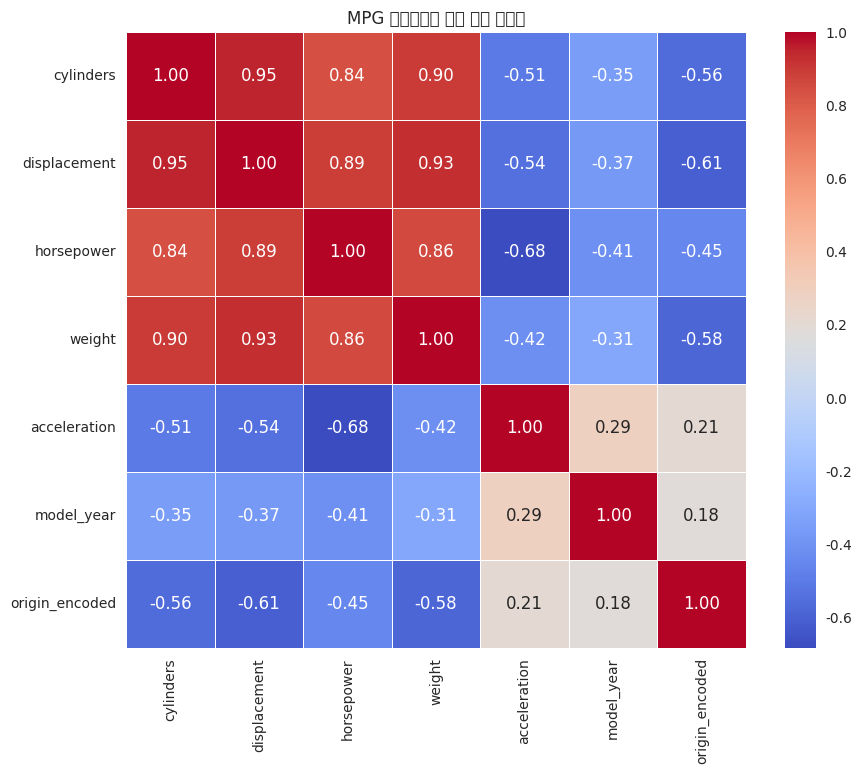

In [21]:
# matplotlib 라이브러리 사용
plt.figure(figsize=(10, 8)) # 그래프 전체 크기 설정 (matplotlib)

# 상관관계 히트맵 그래프 생성 (seaborn)
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5) # seaborn 라이브러리 사용
plt.title('MPG 데이터셋의 상관 관계 히트맵')  # 그래프 제목 설정 (matplotlib)
plt.show() # 그래프 출력 (matplotlib)

```text
# 상관관계 히트맵 그래프 생성 (seaborn)
sns.heatmap(
    corr_matrix,          # 상관관계 데이터
    annot=True,           # 숫자 값 표시
    cmap='coolwarm',      # 색상 스타일 설정
    fmt='.2f',            # 소수점 2자리 표시
    linewidths=.5         # 칸 사이 선 두께
)
```

| 값            | 색   |
| ------------ | --- |
| 큰 양수(+1 가까움) | 빨간색 |
| 0 근처         | 흰색  |
| 큰 음수(-1 가까움) | 파란색 |


| 숫자 | 의미       | 색  |
| -- | -------- | -- |
| 1  | 완전 같은 방향 | 빨강 |
| 0  | 관계 없음    | 흰색 |
| -1 | 완전 반대 방향 | 파랑 |
#
자기 자신 = 완전히 동일 = 상관계수 1

In [22]:
"""
빨강 : 같이 증가 (양의 상관)
파랑 : 반대로 움직임 (음의 상관)
하얀색/연한색 : 관계 약함
cylinders ↔ weight = 🔴 0.90  : 실린더 많으면 무게도 큼
horsepower ↔ acceleration = 🔵 -0.68  : 마력이 높으면 가속시간은 짧아짐 (반대)
빨강 = 같이 움직임, 파랑 = 반대로 움직임
0.7 이상 : 강한 관계, 0.3 ~ 0.7 : 보통, 0.3 이하 : 약함
비슷한 애들은 하나만 남기고 줄이는 게 핵심

1) 먼저 그룹 나누기 :🔴 서로 너무 비슷한 그룹
cylinders, displacement, horsepower, weight : 이 4개는 거의 같은 의미 (중복)
2 ) 선택 이중에서 1~2개만 선택 : weight + horsepower - 이유: 해석도 쉽고, 영향력 큼
3)  나머지 변수 따로 가져감
빨간것에서 추려내고 파란거는 따로 변수로 취급
🔴 빨강 = 줄이기,  🔵 파랑 = 같이 써도 됨
"""

'\n빨강 : 같이 증가 (양의 상관)\n파랑 : 반대로 움직임 (음의 상관)\n하얀색/연한색 : 관계 약함\ncylinders ↔ weight = 🔴 0.90  : 실린더 많으면 무게도 큼\nhorsepower ↔ acceleration = 🔵 -0.68  : 마력이 높으면 가속시간은 짧아짐 (반대)\n빨강 = 같이 움직임, 파랑 = 반대로 움직임\n0.7 이상 : 강한 관계, 0.3 ~ 0.7 : 보통, 0.3 이하 : 약함\n비슷한 애들은 하나만 남기고 줄이는 게 핵심\n\n1) 먼저 그룹 나누기 :🔴 서로 너무 비슷한 그룹\ncylinders, displacement, horsepower, weight : 이 4개는 거의 같은 의미 (중복)\n2 ) 선택 이중에서 1~2개만 선택 : weight + horsepower - 이유: 해석도 쉽고, 영향력 큼\n3)  나머지 변수 따로 가져감\n빨간것에서 추려내고 파란거는 따로 변수로 취급\n🔴 빨강 = 줄이기,  🔵 파랑 = 같이 써도 됨\n'

corr() : 숫자형 속성들을 서로 비교하여 각 속성 간의 관계가 얼마나 강한지 상관계수(-1~+1)로 확인하는 함수

#####  단, 상관관계가 높다고 해서 반드시 원인과 결과라는 뜻은 아니다.
##### 예: weight ↔ cylinders = 0.89 → 둘의 관계가 강하다는 뜻이지, 무조건 실린더가 무게 증가의 원인이라는 뜻은 아니다.

```
corr() = "하나가 변할 때 다른 것도 같이 변하나?" 전부 검사
자동차에 3가지 정보가 있다고 해보자.
```
| 자동차 |   무게 | 연비 |  마력 |
| --- | ---: | -: | --: |
| A   | 1000 | 15 | 100 |
| B   | 1500 | 10 | 150 |
| C   | 2000 |  5 | 200 |
```
corr()은 이렇게 질문한다.
무게가 늘어나네?
   ↓
연비는 어떻게 되지? → 내려가네!
마력은 어떻게 되지? → 올라가네!

연비가 변하네?
   ↓
마력은 어떻게 되지? → 반대로 움직이네!

```
##### corr() = 한 속성이 변할 때 다른 속성도 어떻게 변하는지 모든 숫자 속성을 서로 비교하는 것
##### corr() = 전체 관계를 한눈에 탐색, 그다음 관심 있는 관계를 골라서 자세히 분석

##### mpg와 다른 속성들의 상관관계만 확인
df.corr()['mpg']
